In [1]:
import os, sys, json
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from tqdm import tqdm

sys.path.insert(0, '/Users/faenegoro/Documents/Neuroimaging/BrainOmni')
from brainomni.model import BrainOmni

device = torch.device('mps') if torch.backends.mps.is_available() else torch.device('cpu')
print('Device:', device)

W0707 21:49:45.994000 65552 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Device: mps


In [2]:
CKPT_PATH = '/Users/faenegoro/Documents/Neuroimaging/BrainOmni/ckpt_collection/tiny'
SAVE_DIR  = '../data/preprocessed'
OUT_DIR   = '../results/figures'
os.makedirs(OUT_DIR, exist_ok=True)

with open(os.path.join(CKPT_PATH, 'model_cfg.json')) as f:
    model_config = json.load(f)
base_checkpoint = torch.load(
    os.path.join(CKPT_PATH, 'BrainOmni.pt'), map_location='cpu', weights_only=True
)

proj_out1 = np.load(os.path.join(SAVE_DIR, 'proj_out1.npy'))
proj_out2 = np.load(os.path.join(SAVE_DIR, 'proj_out2.npy'))
labels    = np.load(os.path.join(SAVE_DIR, 'labels.npy'))
split     = np.load(os.path.join(SAVE_DIR, 'split.npz'))
train_idx, val_idx, test_idx = split['train_idx'], split['val_idx'], split['test_idx']

print(f'Loaded {len(proj_out1)} subjects | Shape: {proj_out1.shape}')
print(f'Train: {len(train_idx)} | Val: {len(val_idx)} | Test: {len(test_idx)}')

Loaded 148 subjects | Shape: (148, 16, 160, 256)
Train: 118 | Val: 15 | Test: 15


In [3]:
class CachedMEGDataset(Dataset):
    def __init__(self, indices, cached1, cached2, labels):
        self.indices = indices
        self.cached1 = cached1
        self.cached2 = cached2
        self.labels  = labels
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        idx = self.indices[i]
        return self.cached1[idx], self.cached2[idx], torch.tensor(self.labels[idx], dtype=torch.long)

class FinetuneClassifier(nn.Module):
    def __init__(self, encoder_blocks, hidden_dim=256, dropout=0.3):
        super().__init__()
        self.blocks = encoder_blocks
        self.head = nn.Sequential(
            nn.Linear(hidden_dim * 16, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 2)
        )
    def forward(self, x1, x2):
        x1, x2 = x1.to(device), x2.to(device)
        for block in self.blocks:
            x1 = block(x1)
            x2 = block(x2)
        x1 = F.normalize(x1, p=2.0, dim=-1, eps=1e-6).mean(dim=2)
        x2 = F.normalize(x2, p=2.0, dim=-1, eps=1e-6).mean(dim=2)
        return self.head(((x1 + x2) / 2).flatten(1))

# Regularization configs to test
# Each entry: (label, optimizer_fn, dropout, label_smoothing)
CONFIGS = [
    ('Baseline (Adam, dropout=0.3)',              'adam',  0.3, 0.0),
    ('AdamW wd=0.01, dropout=0.5',               'adamw', 0.5, 0.0),
    ('AdamW wd=0.01, dropout=0.5, LS=0.1',       'adamw', 0.5, 0.1),
    ('AdamW wd=0.1,  dropout=0.5, LS=0.1',       'adamw_strong', 0.5, 0.1),
]

N_FROZEN = 10  # last 1 block unfrozen

print('Helpers ready.')

Helpers ready.


In [4]:
def run_config(label, opt_type, dropout, label_smoothing, max_epochs=200, patience=20):
    print(f'\n=== {label} ===')

    model = BrainOmni(**model_config)
    model.load_state_dict(base_checkpoint, strict=False)
    for param in model.parameters():
        param.requires_grad = False
    model = model.to(device).eval()

    # Cache frozen blocks output
    cached1, cached2 = [], []
    with torch.no_grad():
        for i in tqdm(range(len(proj_out1)), desc='Caching', leave=False):
            x1 = torch.tensor(proj_out1[i]).unsqueeze(0).to(device)
            x2 = torch.tensor(proj_out2[i]).unsqueeze(0).to(device)
            for block in list(model.blocks)[:N_FROZEN]:
                x1 = block(x1)
                x2 = block(x2)
            cached1.append(x1.squeeze(0).cpu())
            cached2.append(x2.squeeze(0).cpu())

    train_loader = DataLoader(CachedMEGDataset(train_idx, cached1, cached2, labels), batch_size=8, shuffle=True)
    val_loader   = DataLoader(CachedMEGDataset(val_idx,   cached1, cached2, labels), batch_size=8)
    test_loader  = DataLoader(CachedMEGDataset(test_idx,  cached1, cached2, labels), batch_size=8)

    unfrozen = nn.ModuleList(list(model.blocks)[N_FROZEN:-1])
    for param in unfrozen.parameters():
        param.requires_grad = True
    ft_model  = FinetuneClassifier(unfrozen, hidden_dim=256, dropout=dropout).to(device)

    if opt_type == 'adam':
        optimizer = torch.optim.Adam(ft_model.parameters(), lr=1e-4)
    elif opt_type == 'adamw':
        optimizer = torch.optim.AdamW(ft_model.parameters(), lr=1e-4, weight_decay=0.01)
    else:  # adamw_strong
        optimizer = torch.optim.AdamW(ft_model.parameters(), lr=1e-4, weight_decay=0.1)

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', factor=0.5, patience=7, min_lr=1e-6
    )
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)

    best_val, patience_count, best_weights = 0, 0, None
    train_accs, val_accs = [], []

    for epoch in range(max_epochs):
        ft_model.train()
        preds, trues = [], []
        for x1, x2, y in train_loader:
            optimizer.zero_grad()
            out  = ft_model(x1, x2)
            loss = criterion(out, y.to(device))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(ft_model.parameters(), max_norm=1.0)
            optimizer.step()
            preds.extend(out.argmax(1).cpu().numpy())
            trues.extend(y.numpy())
        train_acc = accuracy_score(trues, preds)

        ft_model.eval()
        preds, trues = [], []
        with torch.no_grad():
            for x1, x2, y in val_loader:
                out = ft_model(x1, x2)
                preds.extend(out.argmax(1).cpu().numpy())
                trues.extend(y.numpy())
        val_acc = accuracy_score(trues, preds)

        train_accs.append(train_acc)
        val_accs.append(val_acc)

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f'  Epoch {epoch+1:03d} | Train: {train_acc:.3f} | Val: {val_acc:.3f} | LR: {optimizer.param_groups[0]["lr"]:.2e}')

        scheduler.step(val_acc)

        if val_acc > best_val:
            best_val = val_acc
            best_weights = {k: v.clone() for k, v in ft_model.state_dict().items()}
            patience_count = 0
        else:
            patience_count += 1
            if patience_count >= patience:
                print(f'  Early stopping at epoch {epoch+1}')
                break

    ft_model.load_state_dict(best_weights)
    ft_model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for x1, x2, y in test_loader:
            out = ft_model(x1, x2)
            preds.extend(out.argmax(1).cpu().numpy())
            trues.extend(y.numpy())
    test_acc = accuracy_score(trues, preds)
    print(f'  Best val: {best_val:.3f} | Test acc: {test_acc:.3f}')

    return {
        'label': label, 'best_val': best_val, 'test_acc': test_acc,
        'train_accs': train_accs, 'val_accs': val_accs
    }

reg_results = {}
for cfg in CONFIGS:
    label, opt_type, dropout, ls = cfg
    reg_results[label] = run_config(label, opt_type, dropout, ls)


=== Baseline (Adam, dropout=0.3) ===


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  Epoch 001 | Train: 0.525 | Val: 0.533 | LR: 1.00e-04
  Epoch 010 | Train: 0.847 | Val: 0.667 | LR: 1.00e-04
  Epoch 020 | Train: 0.873 | Val: 0.533 | LR: 5.00e-05
  Early stopping at epoch 24
  Best val: 0.667 | Test acc: 0.800

=== AdamW wd=0.01, dropout=0.5 ===


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  Epoch 001 | Train: 0.559 | Val: 0.533 | LR: 1.00e-04
  Epoch 010 | Train: 0.864 | Val: 0.667 | LR: 1.00e-04
  Epoch 020 | Train: 0.873 | Val: 0.667 | LR: 5.00e-05
  Early stopping at epoch 25
  Best val: 0.667 | Test acc: 0.800

=== AdamW wd=0.01, dropout=0.5, LS=0.1 ===


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  Epoch 001 | Train: 0.424 | Val: 0.467 | LR: 1.00e-04
  Epoch 010 | Train: 0.847 | Val: 0.600 | LR: 1.00e-04
  Epoch 020 | Train: 0.890 | Val: 0.600 | LR: 1.00e-04
  Epoch 030 | Train: 0.881 | Val: 0.667 | LR: 5.00e-05
  Early stopping at epoch 34
  Best val: 0.733 | Test acc: 0.867

=== AdamW wd=0.1,  dropout=0.5, LS=0.1 ===


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  Epoch 001 | Train: 0.517 | Val: 0.533 | LR: 1.00e-04
  Epoch 010 | Train: 0.839 | Val: 0.600 | LR: 1.00e-04
  Epoch 020 | Train: 0.881 | Val: 0.600 | LR: 5.00e-05
  Epoch 030 | Train: 0.907 | Val: 0.600 | LR: 2.50e-05
  Early stopping at epoch 31
  Best val: 0.733 | Test acc: 0.867


In [5]:
print('=== Regularization Results (last 1 block unfrozen) ===')
print(f'{"Config":<45} {"Best Val":<12} {"Test Acc"}')
print('-' * 65)
for label, res in reg_results.items():
    print(f'{label:<45} {res["best_val"]:<12.3f} {res["test_acc"]:.3f}')
print()
print('--- Baselines ---')
print('Frozen BrainOmni-tiny + LR (5-fold CV):  0.831')
print('Handcrafted features  + LR (5-fold CV):  0.872')

=== Regularization Results (last 1 block unfrozen) ===
Config                                        Best Val     Test Acc
-----------------------------------------------------------------
Baseline (Adam, dropout=0.3)                  0.667        0.800
AdamW wd=0.01, dropout=0.5                    0.667        0.800
AdamW wd=0.01, dropout=0.5, LS=0.1            0.733        0.867
AdamW wd=0.1,  dropout=0.5, LS=0.1            0.733        0.867

--- Baselines ---
Frozen BrainOmni-tiny + LR (5-fold CV):  0.831
Handcrafted features  + LR (5-fold CV):  0.872


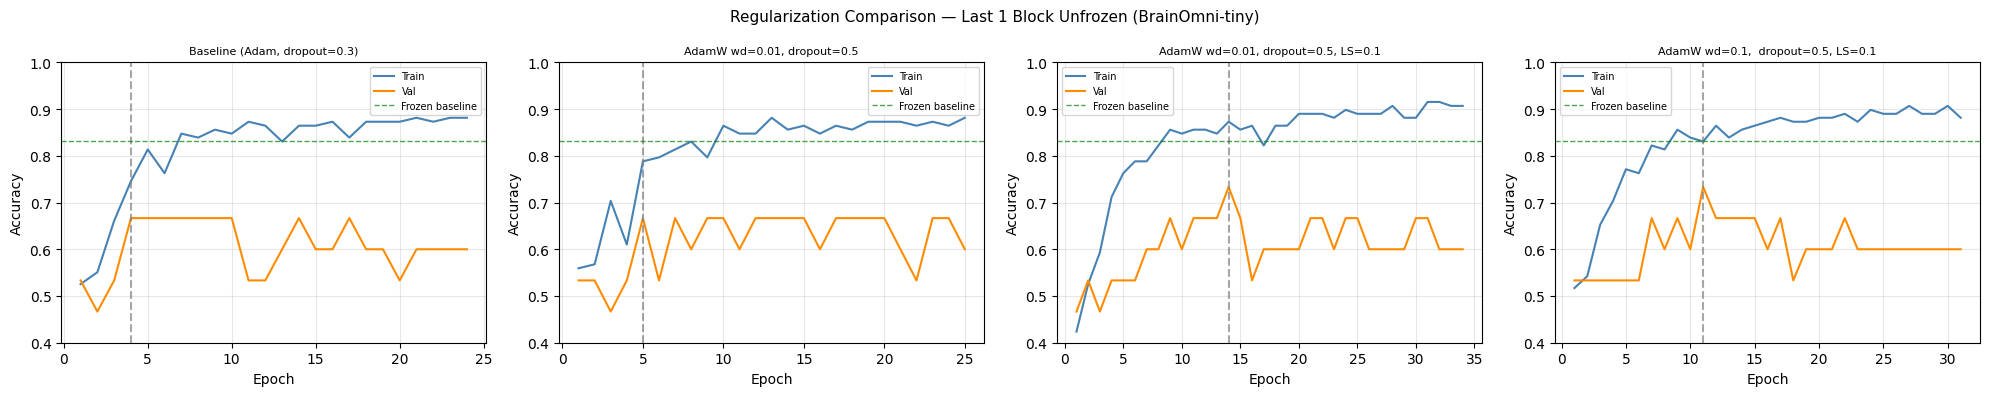

Saved finetune_regularized_curves.png


In [6]:
fig, axes = plt.subplots(1, len(reg_results), figsize=(5 * len(reg_results), 4))

for ax, (label, res) in zip(axes, reg_results.items()):
    epochs   = range(1, len(res['train_accs']) + 1)
    best_ep  = int(np.argmax(res['val_accs'])) + 1
    ax.plot(epochs, res['train_accs'], '-', label='Train', color='steelblue')
    ax.plot(epochs, res['val_accs'],   '-', label='Val',   color='darkorange')
    ax.axvline(best_ep, color='gray', linestyle='--', alpha=0.7)
    ax.axhline(0.831, color='green', linestyle='--', linewidth=1, alpha=0.7, label='Frozen baseline')
    ax.set_title(label, fontsize=8)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Accuracy')
    ax.set_ylim(0.4, 1.0)
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

fig.suptitle('Regularization Comparison — Last 1 Block Unfrozen (BrainOmni-tiny)', fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'finetune_regularized_curves.png'), dpi=150)
plt.show()
print('Saved finetune_regularized_curves.png')